<a href="https://colab.research.google.com/github/sebastianvettel1212/Scikit-Learn-Cookbook/blob/main/scikit_learn_Cookbook_Chapter11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bab 11 — Deteksi *Outlier* dan *Novelty* (*Outlier and Novelty Detection*)

**Buku:** *scikit-learn Cookbook, Third Edition* — John Sukup (Packt Publishing)

Notebook ini berisi:
1. **Reproduksi kode** seluruh *recipe* Bab 11 (dari repositori resmi buku, termasuk solusi latihan),
2. **Ringkasan** tiap subbab, dan
3. **Penjelasan teori** dalam Bahasa Indonesia.

> Sel berlabel **"Tambahan"** adalah contoh pelengkap yang tidak ada di buku. Perbaikan kecil terhadap kode asli buku ditandai dengan komentar `# Catatan:` di dalam sel. Perbaikan paling umum: kode buku memakai angka acak NumPy **tanpa *seed*** pada beberapa sel, sehingga hasilnya tidak bisa direproduksi; di sini ditambahkan `np.random.seed(2024)`.

---

## Daftar Isi
0. Persiapan
1. Memahami Deteksi *Outlier* dan *Novelty* (*Understanding Outlier and Novelty Detection*)
2. *Isolation Forest*
3. *One-Class SVM*
4. *Local Outlier Factor* (LOF)
5. Mengevaluasi Model Deteksi Anomali
6. Menangani *Outlier*
7. Memilih Algoritma yang Tepat
8. Latihan Praktik
9. Ringkasan Bab

---

## Pengantar
Dalam banyak masalah, yang kita cari justru **hal yang jarang dan berbeda**: transaksi kartu kredit curang, mesin yang mulai rusak, serangan jaringan. Kasus ini disebut **deteksi anomali**. Tantangannya: anomali sangat sedikit, bentuknya beragam, dan sering **tidak berlabel**, sehingga klasifikasi terawasi biasa (Bab 6–9) kurang cocok. Bab ini memperkenalkan tiga algoritma unsupervised yang menjadi andalan scikit-learn (*Isolation Forest*, *One-Class SVM*, *Local Outlier Factor*), cara mengevaluasinya, dan cara menangani *outlier* setelah ditemukan.

## 0. Persiapan

In [1]:
!pip install numpy pandas scikit-learn matplotlib seaborn

In [2]:
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print('Versi scikit-learn:', sklearn.__version__)

Versi scikit-learn: 1.6.1


---
## 1. Memahami Deteksi *Outlier* dan *Novelty*

### Teori
Istilah yang sering tertukar:

| | ***Outlier detection*** | ***Novelty detection*** |
|---|---|---|
| **Data latih** | **mengandung** outlier (tidak tahu mana yang outlier) | **bersih**, hanya data normal |
| **Tujuan** | menemukan outlier di dalam data yang sama | mengenali **data baru** yang berbeda dari data normal |
| **Paradigma** | *unsupervised* | *semi-supervised* (satu kelas) |
| **Contoh** | membersihkan data sensor historis | memantau mesin yang sedang berjalan |

Jenis anomali: ***point anomaly*** (satu titik menyimpang jauh), ***contextual anomaly*** (nilai wajar secara umum, tetapi janggal pada konteksnya, mis. suhu 30 °C di musim dingin), dan ***collective anomaly*** (kumpulan titik yang bersama-sama janggal).

Parameter kunci bersama: **`contamination`**, perkiraan proporsi anomali pada data (menentukan ambang keputusan). Algoritma memberi **skor anomali** untuk tiap titik, lalu `contamination` menentukan titik teratas yang ditandai. Keluaran `predict()` scikit-learn: **+1 = inlier** dan **−1 = outlier**.

### Getting ready
Data sintetis: 300 titik normal (satu klaster, simpangan baku 0,6) ditambah 20 titik **anomali acak** yang tersebar seragam pada kotak [−6, 6]².

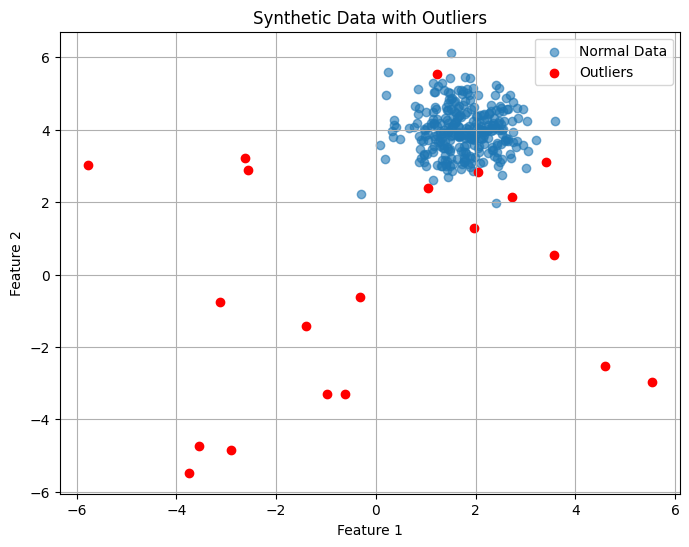

In [3]:
# Load the libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs

# Generate a synthetic dataset with intentional outliers
X, _ = make_blobs(n_samples=300, centers=1, cluster_std=0.60, random_state=2024)
np.random.seed(2024)
outliers = np.random.uniform(low=-6, high=6, size=(20, 2))
X_with_outliers = np.vstack([X, outliers])

# Visualize the data with outliers
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], label="Normal Data", alpha=0.6)
plt.scatter(outliers[:, 0], outliers[:, 1], color='red', label="Outliers")
plt.title("Synthetic Data with Outliers")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

**Interpretasi:** 300 titik normal membentuk satu gugus rapat, sedangkan 20 titik merah tersebar seragam di seluruh kotak [−6, 6]². Sebagian besar titik merah jauh dari gugus normal sehingga mudah dikenali, tetapi karena dibangkitkan acak, ada yang kebetulan jatuh di dalam atau dekat gugus normal (dihitung pada sel Tambahan).

### How to do it...
Untuk memperkenalkan konsepnya, dipakai *Local Outlier Factor* (dibahas rinci pada subbab 4): `contamination=0.05` berarti sekitar 5% titik ditandai sebagai outlier.

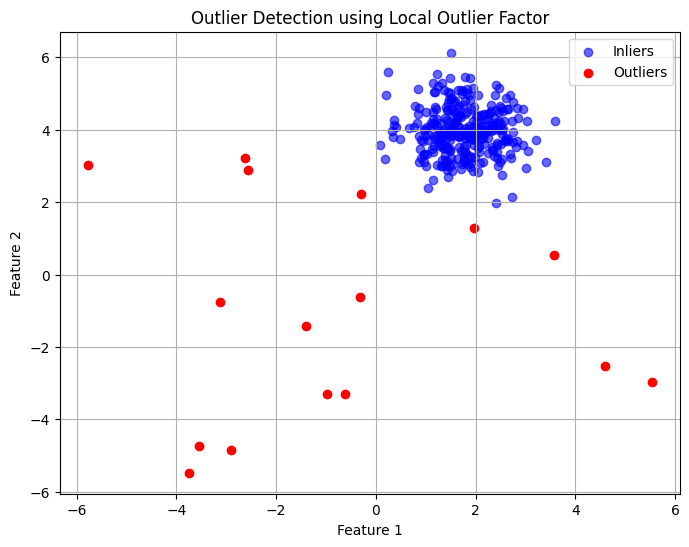

Jumlah titik ditandai outlier: 16 dari 320


In [4]:
# Load the model
from sklearn.neighbors import LocalOutlierFactor

# Fit the model and predict outliers
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.05)
y_pred = lof.fit_predict(X_with_outliers)

# Plot the predictions
plt.figure(figsize=(8, 6))
plt.scatter(X_with_outliers[y_pred == 1, 0], X_with_outliers[y_pred == 1, 1],
            color='blue', label='Inliers', alpha=0.6)
plt.scatter(X_with_outliers[y_pred == -1, 0], X_with_outliers[y_pred == -1, 1],
            color='red', label='Outliers')
plt.title("Outlier Detection using Local Outlier Factor")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()
print('Jumlah titik ditandai outlier:', int((y_pred == -1).sum()), 'dari', len(y_pred))

**Interpretasi:** LOF menandai **16 dari 320** titik sebagai outlier; angka ini bukan kebetulan, melainkan 5% × 320 = 16: parameter `contamination` secara langsung menentukan **berapa banyak** titik yang ditandai (titik dengan skor paling anomali). Titik biru adalah *inlier* dan titik merah *outlier*; titik yang ditandai adalah yang berada jauh dari gugus normal.

### How it works...
Metode deteksi anomali memperkirakan apakah suatu titik berasal dari distribusi yang sama dengan data lain. Titik yang sangat jauh dari wilayah padat, atau berada di wilayah yang jauh lebih jarang daripada tetangganya, mendapat skor anomali tinggi.

### Tambahan: berapa banyak anomali yang sebenarnya *bisa* ditemukan?
Titik "anomali" dibangkitkan **seragam acak**, jadi sebagian bisa kebetulan jatuh di dalam wilayah klaster normal dan secara matematis tidak berbeda dari data normal. Kita hitung batas atas pencapaian model, lalu bandingkan dengan hasil LOF.

In [5]:
# Tambahan (tidak ada di kode buku)
from sklearn.metrics import confusion_matrix

y_true_1 = np.array([0] * len(X) + [1] * len(outliers))          # 0 = normal, 1 = anomali sebenarnya
center = X.mean(axis=0)
r = np.linalg.norm(outliers - center, axis=1)
# Heuristik: pada Gaussian 2D dengan std 0,6, 99,98% data normal berada dalam radius 2,5 dari pusat
inside = r < 2.5
print(f'Anomali yang jatuh di dalam wilayah normal (radius < 2,5 dari pusat): {inside.sum()} dari {len(outliers)}')
print(f'Pada ambang ketat, recall praktis tertahan sekitar {(~inside).sum()}/{len(outliers)} = {(~inside).mean():.0%}; ambang lebih longgar menaikkan recall tetapi menambah alarm palsu')

y_lof = np.where(y_pred == -1, 1, 0)
tn, fp, fn, tp = confusion_matrix(y_true_1, y_lof).ravel()
print(f'LOF (contamination=0.05): TP={tp}, FP={fp}, FN={fn}, TN={tn} | precision={tp/(tp+fp):.2f}, recall={tp/(tp+fn):.2f}')

Anomali yang jatuh di dalam wilayah normal (radius < 2,5 dari pusat): 5 dari 20
Pada ambang ketat, recall praktis tertahan sekitar 15/20 = 75%; ambang lebih longgar menaikkan recall tetapi menambah alarm palsu
LOF (contamination=0.05): TP=15, FP=1, FN=5, TN=299 | precision=0.94, recall=0.75


**Interpretasi:** dari 20 titik anomali, **5 jatuh di dalam wilayah normal** (radius < 2,5 dari pusat), sehingga secara praktis tak dapat dibedakan dari data normal. LOF pada `contamination=0.05` menemukan **15** anomali (TP=15), hanya **1 alarm palsu** (FP=1) dan 5 terlewat (FN=5): precision 0,94 dan recall 0,75. Recall 0,75 tepat sama dengan 15/20, yaitu anomali yang berada di luar wilayah normal. Kesimpulannya, kegagalan menangkap 5 titik terakhir bukan kelemahan algoritma, melainkan karena titik tersebut memang tampak normal. Ini mengingatkan bahwa "recall 100%" tidak selalu mungkin.

### Key Ideas
- ***Outlier detection***: data latih sudah tercemar; ***novelty detection***: data latih bersih dan yang dicari adalah data baru yang aneh.
- Semua metode memberi **skor anomali**; `contamination` mengubah skor menjadi keputusan +1 (normal) / −1 (anomali).
- Tidak semua "anomali" dapat dideteksi: anomali yang jatuh di wilayah data normal tak dapat dibedakan.

---
## 2. *Isolation Forest*

### Teori
Ide ***Isolation Forest***: **anomali mudah "diisolasi"**. Algoritma membangun banyak pohon acak: setiap pembagian memilih fitur acak dan ambang acak di antara nilai minimum dan maksimumnya. Titik yang jarang dan jauh dari yang lain terpisah setelah **sedikit** pembagian (jalur pendek dari akar), sedangkan titik normal yang berkerumun butuh banyak pembagian (jalur panjang). Skor anomali:
$$s(x,n)=2^{-\,\mathbb{E}[h(x)]\,/\,c(n)},\qquad c(n)=2H(n-1)-\frac{2(n-1)}{n}$$
dengan $h(x)$ panjang jalur titik $x$, $c(n)$ panjang jalur rata-rata pencarian gagal pada pohon biner berisi $n$ titik, dan $H(\cdot)$ bilangan harmonik. Skor mendekati **1 = anomali**, jauh di bawah 0,5 = normal. (`decision_function` scikit-learn adalah versi digeser: **negatif = anomali**.)

Kelebihan: cepat (kompleksitas hampir linear), tidak memakai jarak sehingga baik pada **dimensi tinggi** dan data besar, serta tidak perlu *scaling*. Kelemahan: kurang peka pada anomali **lokal** di antara klaster dengan kepadatan berbeda, dan hasilnya bergantung pada `contamination`.

### Getting ready
Data yang sama dengan subbab 1 (300 normal + 20 anomali).

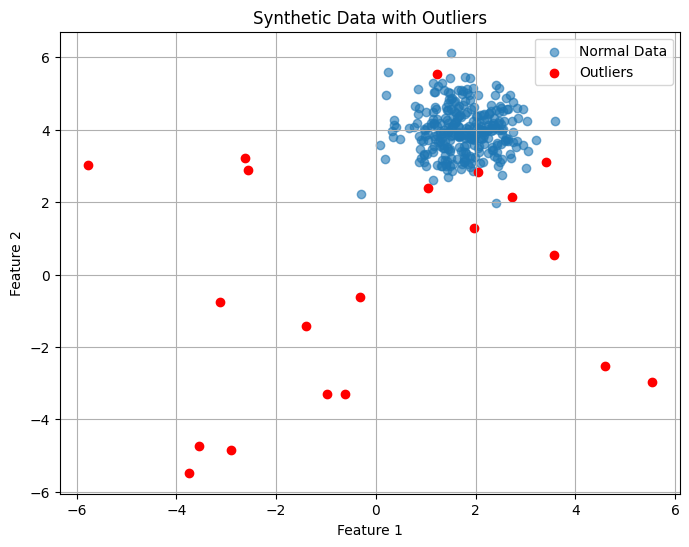

In [6]:
# Load the libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.datasets import make_blobs

# Generate synthetic data with outliers
X, _ = make_blobs(n_samples=300, centers=1, cluster_std=0.6, random_state=2024)
np.random.seed(2024)
outliers = np.random.uniform(low=-6, high=6, size=(20, 2))
X_combined = np.vstack([X, outliers])
y_true_2 = np.array([0] * len(X) + [1] * len(outliers))

# Visualize the data
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], label="Normal Data", alpha=0.6)
plt.scatter(outliers[:, 0], outliers[:, 1], color='red', label="Outliers")
plt.title("Synthetic Data with Outliers")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

### How to do it...
Kita memakai `IsolationForest()` dengan 100 pohon dan `contamination=0.05`.

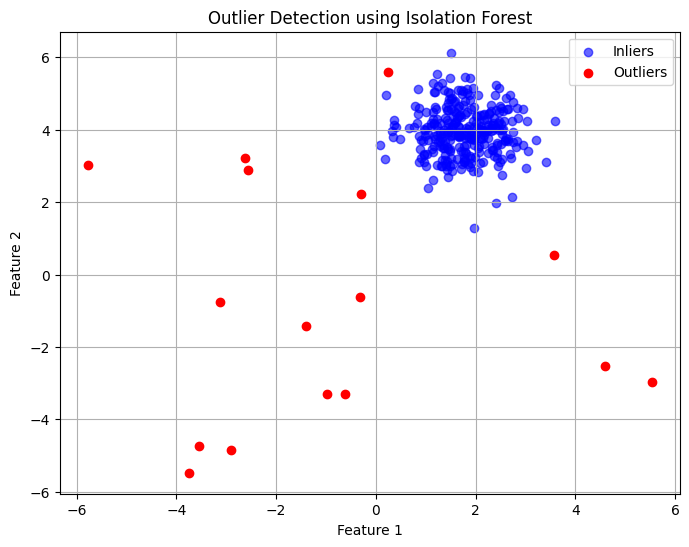

Jumlah titik ditandai outlier: 16 dari 320


In [7]:
# Load and configure the model
model = IsolationForest(n_estimators=100, contamination=0.05, random_state=2024)

# Fit the model and make predictions
model.fit(X_combined)
y_pred = model.predict(X_combined)

# Plot the results
plt.figure(figsize=(8, 6))
plt.scatter(X_combined[y_pred == 1, 0], X_combined[y_pred == 1, 1],
            color='blue', label='Inliers', alpha=0.6)
plt.scatter(X_combined[y_pred == -1, 0], X_combined[y_pred == -1, 1],
            color='red', label='Outliers')
plt.title("Outlier Detection using Isolation Forest")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()
print('Jumlah titik ditandai outlier:', int((y_pred == -1).sum()), 'dari', len(y_pred))

**Interpretasi:** *Isolation Forest* juga menandai **16 dari 320** titik (5%), dengan alasan yang sama: `contamination` menentukan jumlah titik teratas yang dijadikan anomali. Titik merah berada di tepi dan di luar gugus normal, titik yang sangat mudah diisolasi dengan sedikit pembagian acak.

### How it works...
*Isolation Forest* mengisolasi anomali, bukan memodelkan data normal. Berikut sebaran skor anomali dan pengaruh `contamination`, dibandingkan dengan label sebenarnya.

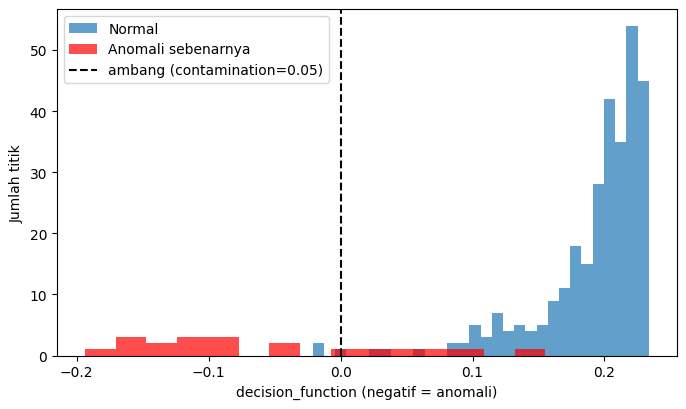

,Ditandai,TP,FP,FN,Precision,Recall
contamination,,,,,,
0.0200,7,7,0,13,1.000,0.35
0.0500,16,14,2,6,0.875,0.70
0.0625,20,15,5,5,0.750,0.75
0.1000,32,19,13,1,0.594,0.95
0.1500,48,19,29,1,0.396,0.95


In [8]:
# Tambahan (tidak ada di kode buku): sebaran skor dan pengaruh contamination
scores = model.decision_function(X_combined)   # negatif = lebih anomali
plt.figure(figsize=(8, 4.5))
plt.hist(scores[y_true_2 == 0], bins=30, alpha=0.7, label='Normal')
plt.hist(scores[y_true_2 == 1], bins=15, alpha=0.7, color='red', label='Anomali sebenarnya')
plt.axvline(0, color='k', linestyle='--', label='ambang (contamination=0.05)')
plt.xlabel('decision_function (negatif = anomali)'); plt.ylabel('Jumlah titik'); plt.legend(); plt.show()

rows = []
for cont in [0.02, 0.05, 0.0625, 0.10, 0.15]:
    m = IsolationForest(contamination=cont, random_state=2024).fit(X_combined)
    flag = (m.predict(X_combined) == -1)
    tp = int((flag & (y_true_2 == 1)).sum()); fp = int((flag & (y_true_2 == 0)).sum()); fn = int((~flag & (y_true_2 == 1)).sum())
    rows.append({'contamination': cont, 'Ditandai': int(flag.sum()), 'TP': tp, 'FP': fp, 'FN': fn,
                 'Precision': tp / max(flag.sum(), 1), 'Recall': tp / (tp + fn)})
pd.DataFrame(rows).set_index('contamination').round(3)

**Interpretasi:** `contamination` adalah **ambang pada peringkat skor**, bukan ukuran kualitas model, dan mengatur *trade-off* precision-recall:
- `0.02` (7 titik ditandai): precision **1,00**, recall hanya 0,35.
- `0.05` (16): precision 0,875, recall 0,70 (14 dari 20).
- `0.0625` (20, sama dengan proporsi anomali sebenarnya): precision = recall = 0,75.
- `0.10` (32): recall naik ke **0,95** (19 dari 20), tetapi precision turun ke 0,594 (13 alarm palsu).
- `0.15` (48): recall tetap 0,95, precision jatuh ke 0,396 (29 alarm palsu).

Perhatikan recall **berhenti naik di 0,95**: satu anomali tersisa tersembunyi di tengah gugus normal, dan menaikkan `contamination` lebih jauh hanya menambah alarm palsu. Pada praktiknya `contamination` ditetapkan dari perkiraan proporsi anomali dan biaya tiap jenis kesalahan.

### Key Ideas
- *Isolation Forest* menandai titik yang **mudah diisolasi** (jalur pohon pendek) sebagai anomali.
- Cepat, skalabel, tidak butuh *scaling*, dan bagus untuk dimensi tinggi.
- `contamination` menentukan **ambang**; nilai yang salah menukar *precision* dengan *recall*.

---
## 3. *One-Class SVM*

### Teori
***One-Class SVM*** adalah algoritma **novelty detection**: dilatih **hanya pada data normal**, lalu memutuskan apakah titik baru "serupa" atau "berbeda". Ia memetakan data lewat kernel (biasanya RBF) dan mencari *hyperplane* yang **memisahkan data dari titik asal** dengan margin maksimum, sehingga membentuk batas tertutup di sekitar wilayah normal di ruang asli. Parameter penting:

- **`nu` ($\nu\in(0,1]$):** batas atas proporsi data latih yang boleh jatuh di luar batas (dianggap anomali) sekaligus batas bawah proporsi *support vector*. `nu=0.05` berarti ≈ 5% data latih berada di luar.
- **`kernel`** dan **`gamma`:** menentukan kelenturan batas (`gamma` besar = batas sempit/bergerigi, Bab 7).

Karena memakai kernel, ia peka terhadap **skala fitur** (perlu standardisasi), kurang skalabel pada data besar, dan tidak menyediakan "skor probabilitas" yang terkalibrasi.

### Getting ready
Data latih: 300 titik normal. Data uji: 100 titik normal (dari pembangkit lain) ditambah 20 titik "novelty" acak.

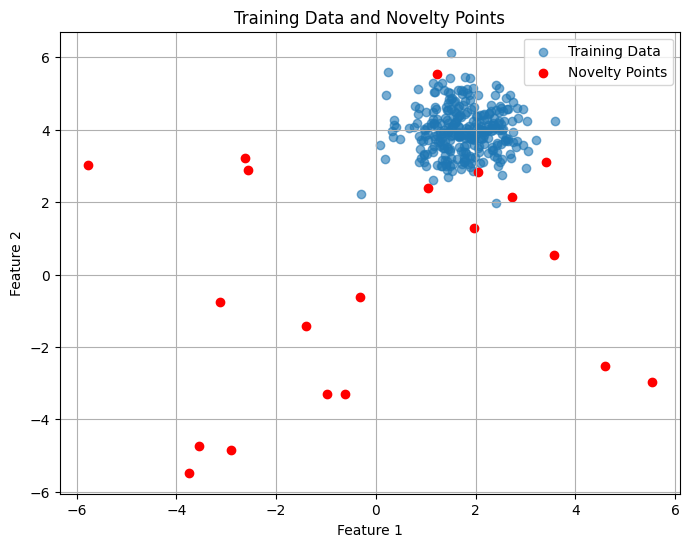

Pusat data latih       : [1.76 3.98]
Pusat "normal" data uji: [0.3  0.98]


In [9]:
# Load the libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import OneClassSVM
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split

# Generate training data (normal only)
X_train, _ = make_blobs(n_samples=300, centers=1, cluster_std=0.6, random_state=2024)

# Generate test data (normal + novelty)
np.random.seed(2024)   # Catatan: ditambahkan agar titik novelty acak dapat direproduksi
X_test_normal, _ = make_blobs(n_samples=100, centers=1, cluster_std=0.6, center_box=(0, 1), random_state=42)
X_test_novelty = np.random.uniform(low=-6, high=6, size=(20, 2))
X_test = np.vstack([X_test_normal, X_test_novelty])
y_test_true = np.array([0] * 100 + [1] * 20)   # 0 = normal, 1 = novelty

# Visualize the data
plt.figure(figsize=(8, 6))
plt.scatter(X_train[:, 0], X_train[:, 1], label='Training Data', alpha=0.6)
plt.scatter(X_test_novelty[:, 0], X_test_novelty[:, 1], color='red', label='Novelty Points')
plt.title("Training Data and Novelty Points")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()
print('Pusat data latih       :', X_train.mean(axis=0).round(2))
print('Pusat "normal" data uji:', X_test_normal.mean(axis=0).round(2))

**Interpretasi:** pusat data latih berada di sekitar **(1,76; 3,98)**, sedangkan pusat data uji "normal" dari kode buku berada di sekitar **(0,30; 0,98)**, sekitar 3,3 satuan jauhnya, atau ≈ 5 simpangan baku dari gugus latih (std 0,6). Artinya, data uji "normal" pada contoh buku **berasal dari distribusi yang berbeda** dari data latih (pembangkit memakai `center_box=(0, 1)` dan `random_state=42`, sedangkan data latih memakai pusat acak dari `random_state=2024`). Hal ini memengaruhi seluruh hasil berikutnya.

### How to do it...
Melatih `OneClassSVM()` dengan kernel RBF, `nu=0.05`.

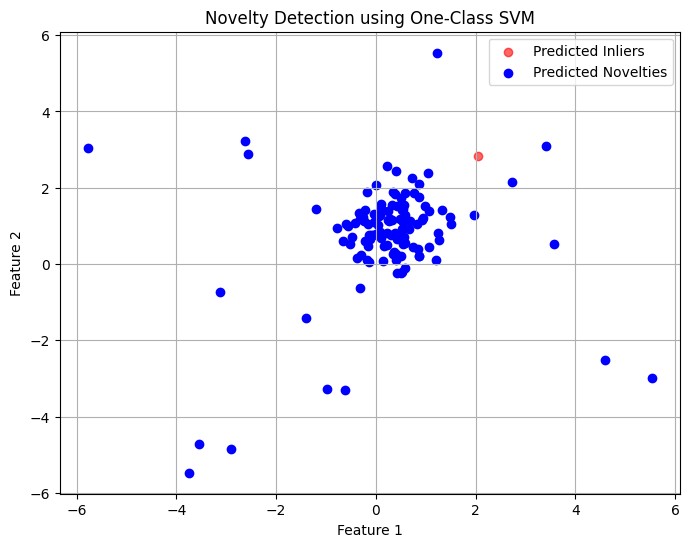

Diprediksi inlier: 1 | diprediksi novelty: 119


In [10]:
# Instantiate and fit the model
model = OneClassSVM(kernel='rbf', gamma='scale', nu=0.05)
model.fit(X_train)

# Make predictions on the test data
y_pred = model.predict(X_test)

# Plot the predictions
plt.figure(figsize=(8, 6))
plt.scatter(X_test[y_pred == 1, 0], X_test[y_pred == 1, 1], color='red', label='Predicted Inliers', alpha=0.6)
plt.scatter(X_test[y_pred == -1, 0], X_test[y_pred == -1, 1], color='blue', label='Predicted Novelties')
plt.title("Novelty Detection using One-Class SVM")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()
print('Diprediksi inlier:', int((y_pred == 1).sum()), '| diprediksi novelty:', int((y_pred == -1).sum()))

**Interpretasi:** model memprediksi **119 dari 120** titik uji sebagai *novelty* dan hanya 1 sebagai *inlier*. Ini **bukan** kegagalan *One-Class SVM*: dari sudut pandang model yang dilatih di sekitar (1,76; 3,98), hampir seluruh titik uji, termasuk yang dilabeli "normal" oleh buku, memang berada jauh di luar wilayah yang dikenalnya. Model bekerja benar, tetapi **contoh ujinya tidak adil**. (Catatan: warna pada kode buku tertukar: "Predicted Inliers" berwarna merah dan "Predicted Novelties" biru; urutan ini dipertahankan agar setia pada kode buku.)

### How it works...
*One-Class SVM* memisahkan data normal dari titik asal di ruang fitur hasil transformasi kernel, dan membentuk batas yang melingkupi wilayah normal. Kita periksa kinerja terhadap label sebenarnya, serta bandingkan dengan data uji normal yang berasal dari distribusi **yang sama** dengan data latih.

In [11]:
# Tambahan (tidak ada di kode buku)
def novelty_report(model, X_te, y_te, title):
    pred = (model.predict(X_te) == -1).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()
    print(f'{title}: normal dikenali benar {tn}/{tn+fp} ({tn/(tn+fp):.0%}) | novelty terdeteksi {tp}/{tp+fn} ({tp/(tp+fn):.0%})')

novelty_report(model, X_test, y_test_true, 'Data uji buku (normal dari pembangkit lain)')

# Data uji normal dari distribusi yang SAMA dengan data latih (pusat sama, std sama)
X_test_same, _ = make_blobs(n_samples=100, centers=[X_train.mean(axis=0)], cluster_std=0.6, random_state=7)
X_test_fair = np.vstack([X_test_same, X_test_novelty])
novelty_report(model, X_test_fair, y_test_true, 'Data uji adil (normal ~ distribusi latih)  ')

# Sensitivitas nu
rows = []
for nu in [0.01, 0.05, 0.1, 0.2]:
    m = OneClassSVM(kernel='rbf', gamma='scale', nu=nu).fit(X_train)
    pred = (m.predict(X_test_fair) == -1).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test_true, pred).ravel()
    rows.append({'nu': nu, 'Latih yang ditolak': float((m.predict(X_train) == -1).mean()), 'Normal salah ditolak (FP)': int(fp), 'Novelty terdeteksi (TP)': int(tp)})
pd.DataFrame(rows).set_index('nu').round(3)

Data uji buku (normal dari pembangkit lain): normal dikenali benar 0/100 (0%) | novelty terdeteksi 19/20 (95%)
Data uji adil (normal ~ distribusi latih)  : normal dikenali benar 96/100 (96%) | novelty terdeteksi 19/20 (95%)


,Latih yang ditolak,Normal salah ditolak (FP),Novelty terdeteksi (TP)
nu,,,
0.01,0.017,0,17
0.05,0.047,4,19
0.10,0.107,7,20
0.20,0.200,19,20


**Interpretasi:**
- **Data uji dari buku:** 0 dari 100 data normal dikenali benar (0%), sedangkan 19 dari 20 *novelty* terdeteksi (95%): semua titik dianggap novelty.
- **Data uji yang adil** (normal dari distribusi yang sama dengan data latih): **96 dari 100** data normal dikenali benar (96%) dan tetap **19 dari 20** novelty terdeteksi (95%). Inilah kinerja *One-Class SVM* yang sebenarnya pada kasus ini.
- **Peran `nu`:** proporsi data latih yang ditolak hampir sama persis dengan `nu` (0,017; 0,047; 0,107; 0,200 untuk `nu` = 0,01; 0,05; 0,1; 0,2). Naiknya `nu` menambah alarm palsu pada data normal (FP: 0, 4, 7, 19) sambil menambah novelty yang terdeteksi (17, 19, 20, 20). `nu=0.2` menolak sekitar seperlima data normal, terlalu longgar; pilih `nu` mendekati proporsi penyimpangan yang dapat diterima.
- **Pelajaran utama:** pada *novelty detection*, jika distribusi data "normal" saat pengujian bergeser, semuanya tampak anomali. Itulah inti pemantauan pergeseran data (*data drift*, dibahas di Bab 13).

### Key Ideas
- *One-Class SVM* dilatih **hanya pada data normal**; cocok untuk *novelty detection*.
- `nu` mengatur proporsi data latih yang boleh dianggap di luar batas; `gamma`/kernel mengatur kelenturan.
- Data uji harus mewakili distribusi normal yang sama; pergeseran distribusi akan dianggap "novelty" semua.

---
## 4. *Local Outlier Factor* (LOF)

### Teori
***Local Outlier Factor*** menilai keanehan sebuah titik **relatif terhadap kepadatan lokal tetangganya**. Langkah-langkahnya:

1. Untuk tiap titik $p$, ambil $k$ tetangga terdekat (`n_neighbors`).
2. Hitung **kepadatan jangkauan lokal** (*local reachability density*): $\text{lrd}(p)=\Big(\dfrac{1}{k}\sum_{o\in N_k(p)}\text{reach-dist}_k(p,o)\Big)^{-1}$.
3. Hitung LOF sebagai rasio kepadatan tetangga terhadap kepadatan titik itu sendiri:
$$\text{LOF}_k(p)=\frac{1}{k}\sum_{o\in N_k(p)}\frac{\text{lrd}(o)}{\text{lrd}(p)}$$

LOF ≈ **1** berarti kepadatan setara tetangga (normal); LOF **≫ 1** berarti titik berada di wilayah jauh lebih jarang daripada tetangganya (anomali). Karena **relatif terhadap kepadatan lokal**, LOF mampu mendeteksi anomali pada data yang klasternya memiliki **kepadatan berbeda**, kasus yang sulit bagi metode berbasis ambang global. scikit-learn menyimpan skor sebagai `negative_outlier_factor_` (makin negatif makin anomali).

Catatan: secara bawaan LOF **tidak** memiliki `predict()` untuk data baru; gunakan `novelty=True` (dengan melatih pada data bersih) bila ingin memakainya sebagai detektor *novelty*. Kelemahan: lambat pada data besar dan kurang baik pada dimensi tinggi; hasil bergantung pada `n_neighbors`.

### Getting ready
Dua klaster dengan **kepadatan berbeda** (simpangan baku 0,5 dan 1,5) ditambah 20 titik anomali acak.

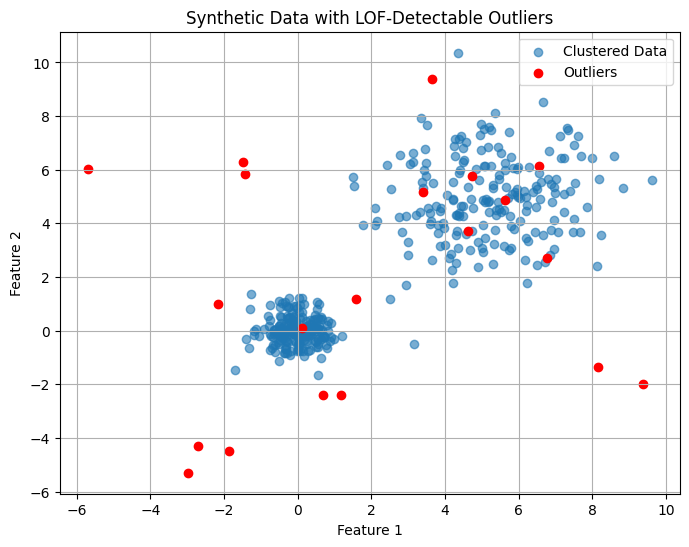

In [12]:
# Load the libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.neighbors import LocalOutlierFactor

# Create synthetic data with clusters and noise
X, _ = make_blobs(n_samples=400, centers=[[0, 0], [5, 5]], cluster_std=[0.5, 1.5], random_state=2024)
np.random.seed(2024)
outliers = np.random.uniform(low=-6, high=10, size=(20, 2))
X_with_outliers = np.vstack([X, outliers])
y_true_4 = np.array([0] * len(X) + [1] * len(outliers))

# Visualize the data
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], label="Clustered Data", alpha=0.6)
plt.scatter(outliers[:, 0], outliers[:, 1], color='red', label="Outliers")
plt.title("Synthetic Data with LOF-Detectable Outliers")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

### How to do it...
Menerapkan `LocalOutlierFactor()` dengan 20 tetangga dan `contamination=0.05`.

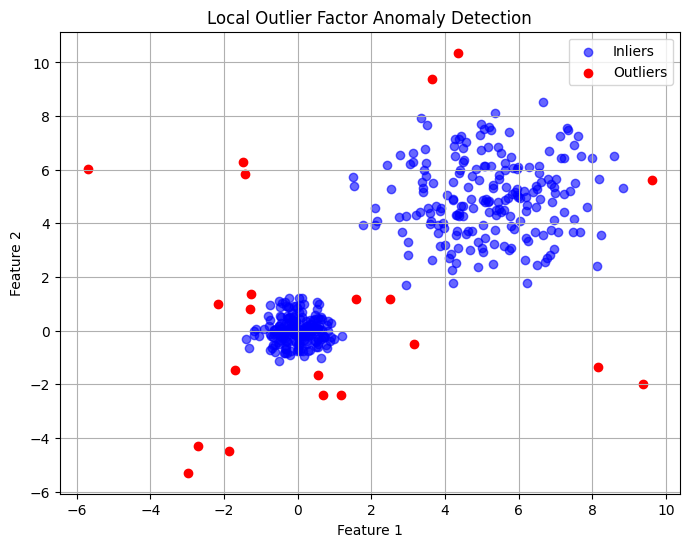

Jumlah titik ditandai outlier: 21 dari 420


In [13]:
# Initialize and fit the model
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.05)
y_pred = lof.fit_predict(X_with_outliers)

# Plot the predictions
plt.figure(figsize=(8, 6))
plt.scatter(X_with_outliers[y_pred == 1, 0], X_with_outliers[y_pred == 1, 1],
            color='blue', label='Inliers', alpha=0.6)
plt.scatter(X_with_outliers[y_pred == -1, 0], X_with_outliers[y_pred == -1, 1],
            color='red', label='Outliers')
plt.title("Local Outlier Factor Anomaly Detection")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()
print('Jumlah titik ditandai outlier:', int((y_pred == -1).sum()), 'dari', len(y_pred))

**Interpretasi:** pada data dua klaster berkepadatan berbeda (klaster rapat dengan std 0,5 dan klaster longgar dengan std 1,5), LOF menandai **21 dari 420** titik (5% × 420). LOF menilai tiap titik terhadap kepadatan tetangganya sendiri, sehingga titik di tepi klaster longgar tidak otomatis dianggap anomali hanya karena jaraknya lebih besar daripada jarak di klaster rapat.

### How it works...
LOF mengevaluasi tingkat keanehan titik lewat tiga hal: **kepadatan lokal** (seberapa rapat tetangga titik itu), **perbandingan dengan tetangga** (kepadatan titik vs kepadatan tetangganya), dan **skor LOF** (≈ 1 normal, ≫ 1 anomali). Berikut pengaruh `n_neighbors` serta penggunaan `novelty=True` untuk data baru.

In [14]:
# Tambahan (tidak ada di kode buku)
from sklearn.metrics import roc_auc_score

rows = []
for k in [5, 10, 20, 40, 80]:
    m = LocalOutlierFactor(n_neighbors=k, contamination=0.05)
    pr = m.fit_predict(X_with_outliers)
    flag = (pr == -1)
    tp = int((flag & (y_true_4 == 1)).sum())
    rows.append({'n_neighbors': k, 'AUC (skor LOF)': roc_auc_score(y_true_4, -m.negative_outlier_factor_),
                 'Ditandai': int(flag.sum()), 'TP': tp, 'Precision': tp / flag.sum()})
display(pd.DataFrame(rows).set_index('n_neighbors').round(3))

# LOF sebagai detektor novelty: latih pada data bersih, lalu prediksi titik baru
lof_nov = LocalOutlierFactor(n_neighbors=20, novelty=True).fit(X)
new_points = np.array([[0.0, 0.0], [5.0, 5.0], [2.5, 2.5], [8.0, -4.0]])
print('Titik baru:', new_points.tolist())
print('Prediksi (1 = normal, -1 = anomali):', lof_nov.predict(new_points))
print('Skor (makin negatif makin anomali):', lof_nov.score_samples(new_points).round(2))

,AUC (skor LOF),Ditandai,TP,Precision
n_neighbors,,,,
5,0.847,21,13,0.619
10,0.827,21,13,0.619
20,0.767,21,13,0.619
40,0.769,21,13,0.619
80,0.766,21,13,0.619


Titik baru: [[0.0, 0.0], [5.0, 5.0], [2.5, 2.5], [8.0, -4.0]]
Prediksi (1 = normal, -1 = anomali): [ 1  1  1 -1]
Skor (makin negatif makin anomali): [-0.97 -0.99 -1.37 -5.23]


**Interpretasi:**
- **Pengaruh `n_neighbors`:** AUC skor LOF turun dari **0,847** (k=5) ke 0,827 (k=10), lalu ≈ 0,77 untuk k = 20, 40, 80. Pada data ini, tetangga yang sedikit lebih baik memisahkan anomali acak yang tersebar jarang; tetangga yang banyak "meratakan" perbedaan kepadatan lokal. (Hasil bergantung pada data dan tidak berlaku umum.) Pada `contamination=0.05`, kelima pengaturan menandai 21 titik dengan 13 benar (precision 0,619), sehingga selisih kualitas peringkat baru terlihat pada AUC.
- **`novelty=True`:** setelah dilatih pada data bersih, LOF dapat menilai titik baru: pusat kedua klaster (0, 0) dan (5, 5) dinyatakan normal, titik jauh (8, −4) dinyatakan anomali dengan skor kuat (−5,23), sedangkan titik (2,5; 2,5) di ruang kosong **antara** dua klaster berskor −1,37, hampir menyentuh ambang bawaan (sekitar −1,5), jadi masih lolos sebagai normal namun sudah "mencurigakan".

### Key Ideas
- LOF membandingkan **kepadatan lokal** sebuah titik dengan kepadatan tetangganya: ≈ 1 normal, ≫ 1 anomali.
- Unggul untuk data dengan **kepadatan antar-klaster berbeda**; sensitif pada `n_neighbors`.
- Untuk memprediksi titik baru, gunakan `novelty=True` dan latih pada data bersih.

---
## 5. Mengevaluasi Model Deteksi Anomali

### Teori
Evaluasi deteksi anomali memerlukan **label sebenarnya** (mis. dari audit atau data simulasi); tanpa label hanya bisa memeriksa secara visual atau lewat pakar domain. Karena anomali sangat langka (**kelas tak seimbang**), **akurasi menyesatkan**: model yang selalu menjawab "normal" pun mendapat akurasi tinggi. Metrik yang tepat (kelas positif = anomali):

| Metrik | Arti dalam konteks anomali |
|---|---|
| **Precision** | dari titik yang ditandai anomali, berapa yang benar-benar anomali (kebalikan *alarm palsu*) |
| **Recall** | dari anomali sebenarnya, berapa yang tertangkap (kebalikan *kasus lolos*) |
| **F1** | rata-rata harmonik keduanya |
| **ROC-AUC** | kemampuan skor memisahkan anomali dari normal pada **semua** ambang |
| **PR-AUC / *average precision*** | lebih informatif daripada ROC-AUC saat kelas sangat tak seimbang |
| ***Confusion matrix*** | rincian TP/FP/FN/TN |

Pilihan metrik mengikuti biaya kesalahan: pada deteksi penipuan, melewatkan penipuan (FN) mahal sehingga *recall* diutamakan; bila setiap alarm harus diselidiki manual (FP mahal), *precision* diutamakan.

### Getting ready
Data berlabel: 300 normal + 30 anomali (≈ 9%).

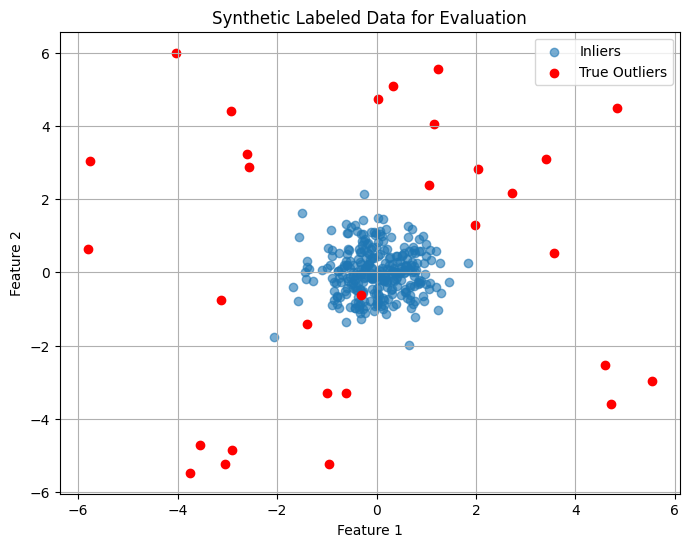

In [15]:
# Load the libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.ensemble import IsolationForest
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import seaborn as sns

# Generate labeled synthetic data
np.random.seed(2024)   # Catatan: ditambahkan agar hasil dapat direproduksi
X_inliers, _ = make_blobs(n_samples=300, centers=[[0, 0]], cluster_std=0.6, random_state=2024)
X_outliers = np.random.uniform(low=-6, high=6, size=(30, 2))
X = np.vstack([X_inliers, X_outliers])
y_true = np.array([0] * len(X_inliers) + [1] * len(X_outliers))  # 0 = inlier, 1 = outlier

# Visualize the data
plt.figure(figsize=(8, 6))
plt.scatter(X[y_true == 0][:, 0], X[y_true == 0][:, 1], label='Inliers', alpha=0.6)
plt.scatter(X[y_true == 1][:, 0], X[y_true == 1][:, 1], color='red', label='True Outliers')
plt.title("Synthetic Labeled Data for Evaluation")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

### How to do it...
Kita melatih *Isolation Forest* dengan `contamination=0.09` (≈ proporsi anomali sebenarnya) lalu mengevaluasinya.

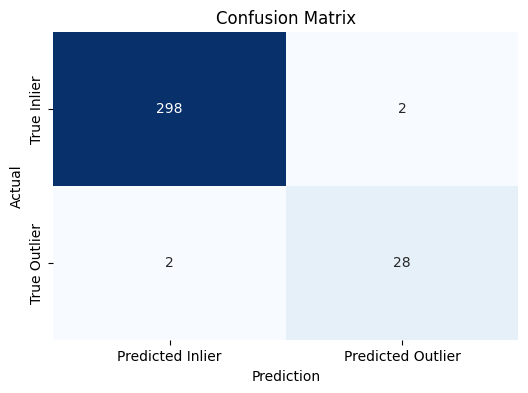

,precision,recall,f1-score,support
0,0.993,0.993,0.993,300
1,0.933,0.933,0.933,30
accuracy,0.988,0.988,0.988,1
macro avg,0.963,0.963,0.963,330
weighted avg,0.988,0.988,0.988,330


ROC-AUC Score: 0.9785555555555555


In [16]:
import pandas as pd

# Fit the model and get predictions
model = IsolationForest(contamination=0.09, random_state=2024)
model.fit(X)
y_pred = model.predict(X)
y_pred_binary = np.where(y_pred == 1, 0, 1)  # convert to 0 = inlier, 1 = outlier

# Generate and plot confusion matrix
cm = confusion_matrix(y_true, y_pred_binary)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted Inlier', 'Predicted Outlier'],
            yticklabels=['True Inlier', 'True Outlier'])
plt.xlabel('Prediction')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

# Print classification report as a styled DataFrame and AUC
report = classification_report(y_true, y_pred_binary, output_dict=True)
report = pd.DataFrame(report).transpose()
styled_report = (report
    .style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
display(styled_report)
print("ROC-AUC Score:", roc_auc_score(y_true, -model.decision_function(X)))   # Catatan: tanda minus agar skor tinggi = anomali (kode buku tanpa minus menghasilkan AUC terbalik)

**Interpretasi:** *Isolation Forest* (`contamination=0.09`) mencapai akurasi **0,988**; untuk kelas anomali, precision = recall = **0,933** (28 dari 30 anomali tertangkap, 2 alarm palsu, 2 terlewat). ROC-AUC **0,979**. Catatan penting: kode buku memanggil `roc_auc_score(y_true, model.decision_function(X))` tanpa membalik tanda. Karena pada scikit-learn skor `decision_function` **makin negatif makin anomali**, sedangkan `roc_auc_score` mengira skor makin besar makin positif (anomali), AUC yang dihasilkan terbalik (≈ 0,021 = 1 − 0,979). Pada notebook ini skor diberi tanda minus.

### How it works...
Setiap metrik memberi sudut pandang berbeda: **precision** (ketepatan alarm), **recall** (kelengkapan penangkapan), **F1** (keseimbangan), **ROC-AUC** (kemampuan membedakan di semua ambang). Pada data tak seimbang, bandingkan juga dengan *baseline* sederhana:

Akurasi baseline "selalu normal": 0.909 | akurasi model: 0.988
ROC-AUC = 0.979 | PR-AUC (average precision) = 0.961 | proporsi anomali = 0.091


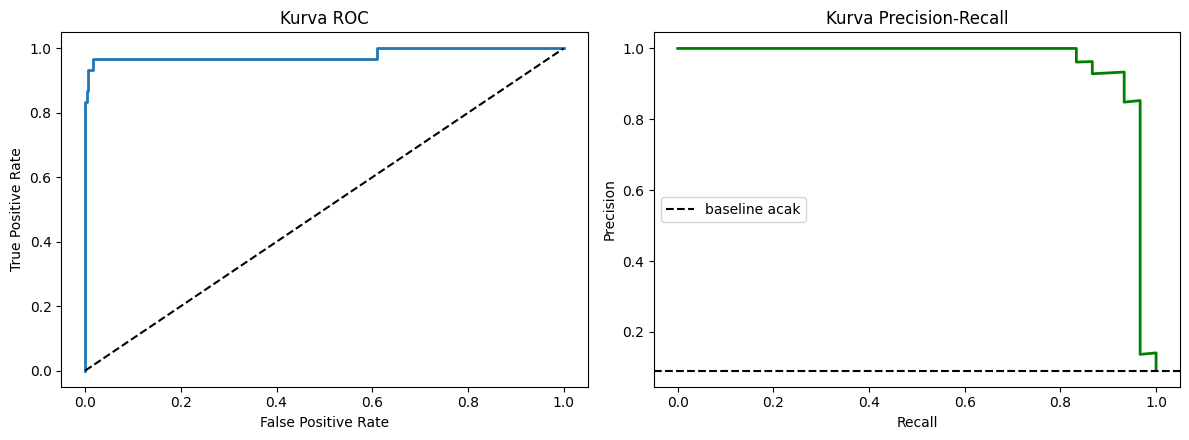

In [17]:
# Tambahan (tidak ada di kode buku)
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_curve

anom_score = -model.decision_function(X)           # makin besar = makin anomali
baseline_acc = (y_true == 0).mean()
model_acc = (y_pred_binary == y_true).mean()
print(f'Akurasi baseline "selalu normal": {baseline_acc:.3f} | akurasi model: {model_acc:.3f}')
print(f'ROC-AUC = {roc_auc_score(y_true, anom_score):.3f} | PR-AUC (average precision) = {average_precision_score(y_true, anom_score):.3f} | proporsi anomali = {y_true.mean():.3f}')

fpr, tpr, _ = roc_curve(y_true, anom_score)
prec, rec, _ = precision_recall_curve(y_true, anom_score)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(fpr, tpr, lw=2); ax[0].plot([0, 1], [0, 1], 'k--'); ax[0].set_xlabel('False Positive Rate'); ax[0].set_ylabel('True Positive Rate'); ax[0].set_title('Kurva ROC')
ax[1].plot(rec, prec, lw=2, color='green'); ax[1].axhline(y_true.mean(), color='k', linestyle='--', label='baseline acak'); ax[1].set_xlabel('Recall'); ax[1].set_ylabel('Precision'); ax[1].set_title('Kurva Precision-Recall'); ax[1].legend()
plt.tight_layout(); plt.show()

**Interpretasi:** model yang **selalu menjawab "normal"** sudah mendapat akurasi **0,909**, sedangkan model sungguhan 0,988, selisih hanya ≈ 8 poin padahal model menemukan 93% anomali dan *baseline* 0%: **akurasi menyembunyikan perbedaan terpenting**. PR-AUC (*average precision*) model **0,961**, sekitar 10× proporsi anomali (0,091, yaitu skor kurva PR model acak), memberi gambaran lebih jujur. Pada kurva PR, *precision* = 1,00 sampai *recall* 0,8, lalu 0,93 pada *recall* 0,9 dan 0,85 pada *recall* 0,95, tetapi **anjlok ke ≈ 0,14** hanya demi menangkap seluruh 30 anomali: beberapa anomali terakhir tersamar di tengah data normal, selaras dengan tabel `contamination` pada subbab 2.

### Key Ideas
- Pada data tak seimbang, **akurasi menyesatkan**; pakai precision, recall, F1, ROC-AUC, dan terutama **PR-AUC**.
- Pastikan arah skor benar: `decision_function` scikit-learn **negatif = anomali**, sehingga untuk AUC skor perlu dibalik.
- Pilih metrik sesuai biaya kesalahan (alarm palsu vs kasus terlewat).

---
## 6. Menangani *Outlier*

### Teori
Setelah anomali ditemukan, apa yang dilakukan bergantung pada **penyebabnya** dan tujuan analisis. Strategi yang dibahas buku:

| Strategi | Cara | Cocok bila | Risiko |
|---|---|---|---|
| **Menghapus** | buang baris yang ditandai | anomali adalah kesalahan pengukuran/entri | kehilangan informasi bila ternyata kejadian nyata |
| **Mengganti (imputasi)** | ganti dengan median/rata-rata dari data normal | ingin menjaga jumlah sampel | mengurangi variansi alami |
| ***Capping* / *winsorization*** | batasi nilai pada persentil bawah/atas (mis. 5% dan 95%) | ingin mengurangi pengaruh nilai ekstrem tanpa membuang data | mengubah **semua** nilai di ekor, termasuk data normal |
| **Menandai (*flagging*)** | tambah fitur biner "anomali?" | anomali itu sendiri informatif bagi model | menambah dimensi |
| **Membiarkan** | gunakan model yang tahan *outlier* | anomali adalah bagian sah dari proses | model sensitif akan terganggu |

Prinsip utama: **jangan menghapus *outlier* secara membabi buta**; selidiki dulu apakah ia kesalahan atau sinyal penting (penipuan, kerusakan mesin, fenomena langka justru yang dicari).

### Getting ready
Data berlabel dari subbab 5, dengan *Isolation Forest* untuk menandai anomali.

In [18]:
# Load the libraries
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.datasets import make_blobs

# Generate the dataset
np.random.seed(2024)   # Catatan: ditambahkan agar hasil dapat direproduksi
X_inliers, _ = make_blobs(n_samples=300, centers=[[0, 0]], cluster_std=0.6, random_state=2024)
X_outliers = np.random.uniform(low=-6, high=6, size=(30, 2))
X = np.vstack([X_inliers, X_outliers])

#  Detect outliers using Isolation Forest
model = IsolationForest(contamination=0.09, random_state=2024)
model.fit(X)
outlier_mask = model.predict(X) == -1
print('Titik ditandai outlier:', int(outlier_mask.sum()), 'dari', len(X))

Titik ditandai outlier: 30 dari 330


### How to do it...
Kita menerapkan tiga strategi: hapus, ganti dengan median, dan *capping* (winsorization pada persentil 5% dan 95%).

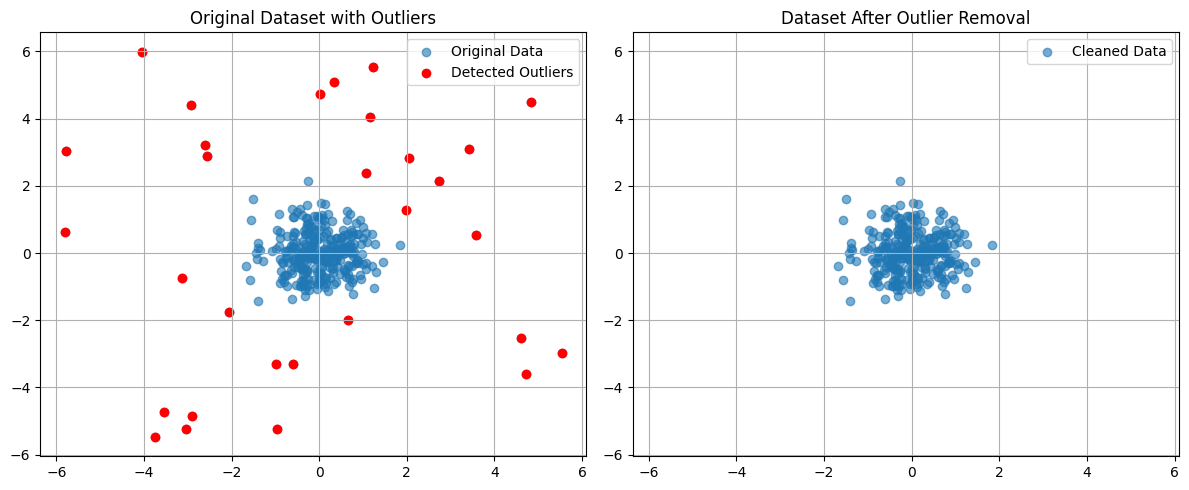

In [19]:
# Remove outliers from the dataset
X_cleaned = X[~outlier_mask]

# Replace outliers with the feature-wise median
X_replaced = X.copy()
median_vals = np.median(X[~outlier_mask], axis=0)
X_replaced[outlier_mask] = median_vals

# Cap outliers to specified bounds (winsorization)
X_df = pd.DataFrame(X, columns=['feature1', 'feature2'])
X_capped = X_df.copy()
for col in X_df.columns:
    lower = X_df[col].quantile(0.05)
    upper = X_df[col].quantile(0.95)
    X_capped[col] = X_df[col].clip(lower=lower, upper=upper)

# Visualize original and cleaned datasets with matched axes
plt.figure(figsize=(12, 5))

ax1 = plt.subplot(1, 2, 1)
ax1.scatter(X[:, 0], X[:, 1], label='Original Data', alpha=0.6)
ax1.scatter(X[outlier_mask][:, 0], X[outlier_mask][:, 1], color='red', label='Detected Outliers')
ax1.set_title('Original Dataset with Outliers')
ax1.legend()
ax1.grid(True)

ax2 = plt.subplot(1, 2, 2)
ax2.scatter(X_cleaned[:, 0], X_cleaned[:, 1], label='Cleaned Data', alpha=0.6)
ax2.set_title('Dataset After Outlier Removal')
ax2.legend()
ax2.grid(True)

ax2.set_xlim(ax1.get_xlim())
ax2.set_ylim(ax1.get_ylim())

plt.tight_layout()
plt.show()

**Interpretasi:** *Isolation Forest* menandai 30 dari 330 titik (9%). Setelah dihapus, data tersisa berupa gugus rapat tanpa pencilan, sedangkan titik merah pada gambar kiri tersebar di sekeliling gugus. Penghapusan paling "bersih", tetapi hanya tepat bila titik tersebut benar-benar kesalahan, bukan kejadian nyata yang penting.

### How it works...
Pemilihan strategi bergantung pada asumsi data dan dampak outlier pada analisis. Berikut perbandingan numerik semua strategi (termasuk *flagging*).

In [20]:
# Tambahan (tidak ada di kode buku)
stats = pd.DataFrame({
    'Asli': pd.DataFrame(X).agg(['mean', 'std']).T.stack(),
    'Dihapus': pd.DataFrame(X_cleaned).agg(['mean', 'std']).T.stack(),
    'Diganti median': pd.DataFrame(X_replaced).agg(['mean', 'std']).T.stack(),
    'Capping 5-95%': pd.DataFrame(X_capped.values).agg(['mean', 'std']).T.stack(),
})
stats.index = [f'fitur {i+1} - {s}' for i, s in stats.index]
display(stats.round(3))

# Berapa nilai yang diubah oleh tiap strategi?
changed_cap = int((X_capped.values != X).sum())
print(f'Capping mengubah {changed_cap} dari {X.size} nilai ({changed_cap / X.size:.1%}), padahal hanya {outlier_mask.sum()} titik ({outlier_mask.mean():.1%}) yang terdeteksi sebagai outlier.')

# Strategi menandai (flagging): tambahkan fitur indikator
X_flagged = np.column_stack([X, outlier_mask.astype(int)])
print('Bentuk data setelah flagging:', X_flagged.shape, '| 3 baris terakhir:')
print(X_flagged[-3:].round(2))

,Asli,Dihapus,Diganti median,Capping 5-95%
fitur 1 - mean,-0.022,-0.001,-0.003,-0.017
fitur 1 - std,1.129,0.611,0.583,0.675
fitur 2 - mean,0.036,0.004,0.002,0.030
fitur 2 - std,1.274,0.626,0.597,0.697


Capping mengubah 68 dari 660 nilai (10.3%), padahal hanya 30 titik (9.1%) yang terdeteksi sebagai outlier.
Bentuk data setelah flagging: (330, 3) | 3 baris terakhir:
[[-3.05 -5.23  1.  ]
 [ 4.83  4.49  1.  ]
 [-4.04  6.    1.  ]]


**Interpretasi:**
- **Dampak pada simpangan baku:** data asli 1,129 dan 1,274; setelah **dihapus** turun ke 0,611 dan 0,626 (mendekati std 0,6 gugus normal yang sebenarnya); **diganti median** 0,583 dan 0,597 (sedikit terlalu kecil karena banyak nilai ditumpuk di median); **capping** hanya turun ke 0,675 dan 0,697 (nilai ekstrem masih menyisakan sebaran). Rata-rata nyaris tidak berubah (mendekati 0) karena anomali tersebar simetris.
- ***Capping* mengubah data normal juga:** 68 dari 660 nilai (10,3%) diubah, padahal hanya 30 titik (9,1%) yang terdeteksi sebagai outlier. Batas persentil 5% dan 95% diterapkan ke semua titik tanpa melihat hasil detektor, jadi sebagian data normal ikut terpotong.
- ***Flagging*** menambahkan kolom ketiga (1 = ditandai outlier) tanpa mengubah nilai asli, sehingga model dapat belajar sendiri apakah status "anomali" itu informatif.

### Key Ideas
- Pilih strategi (hapus, ganti, *capping*, tandai, biarkan) berdasarkan **penyebab** dan **tujuan** analisis.
- *Capping* mengubah juga data normal di ekor distribusi; hapus/ganti hanya menyentuh titik yang terdeteksi.
- **Selidiki dulu** sebelum membuang: anomali bisa justru kejadian yang paling penting.

---
## 7. Memilih Algoritma yang Tepat

### Teori
Tabel ringkasan dari buku (isi tabel dibuat ulang pada kode berikut), dilanjutkan pembuktian empiris.

In [21]:
# Load the libraries
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM

# Create a comparison table of methods
data = {
    "Algorithm": ["Isolation Forest", "Local Outlier Factor", "One-Class SVM"],
    "Handles High Dimensions": ["Yes", "No", "Sometimes"],
    "Learns From Unlabeled Data": ["Yes", "Yes", "No (novelty only)"],
    "Supports New Predictions": ["Yes", "No", "Yes"],
    "Scales to Large Data": ["Yes", "No", "No"],
    "Robust to Varying Densities": ["No", "Yes", "Partially"],
    "Main Strength": [
        "Fast, scalable, easy to use",
        "Detects local anomalies in varying densities",
        "Kernel-based boundary modeling"
    ]
}

summary_df = pd.DataFrame(data)
summary_df.set_index("Algorithm", inplace=True)
summary_df

,Handles High Dimensions,Learns From Unlabeled Data,Supports New Predictions,Scales to Large Data,Robust to Varying Densities,Main Strength
Algorithm,,,,,,
Isolation Forest,Yes,Yes,Yes,Yes,No,"Fast, scalable, easy to use"
Local Outlier Factor,No,Yes,No,No,Yes,Detects local anomalies in varying densities
One-Class SVM,Sometimes,No (novelty only),Yes,No,Partially,Kernel-based boundary modeling


### How to do it...
Contoh kriteria keputusan (kode berikut hanya mendefinisikan model sesuai skenario):

In [22]:
# If your data is large and high-dimensional, consider:
# Isolation Forest is preferred
model = IsolationForest(contamination=0.1, random_state=2024)

#If your data has clusters with varying densities:
# Local Outlier Factor is better suited
model = LocalOutlierFactor(n_neighbors=20, contamination=0.1)

# If you want to train on only normal data and detect novel data points later:
# One-Class SVM enables novelty detection
model = OneClassSVM(kernel='rbf', gamma='scale', nu=0.1)
print('Tiga model berhasil dibuat:', type(model).__name__, '(model terakhir)')

Tiga model berhasil dibuat: OneClassSVM (model terakhir)


### How it works...
- **Isolation Forest:** cepat dan skalabel; kuat untuk data besar berdimensi tinggi, tetapi kurang peka pada anomali lokal di antara klaster berkepadatan berbeda.
- **LOF:** unggul pada anomali lokal dengan kepadatan beragam, tetapi lambat pada data besar dan kurang baik pada dimensi tinggi.
- **One-Class SVM:** fleksibel lewat kernel dan cocok untuk *novelty detection*; peka terhadap hiperparameter dan *scaling*, serta lambat pada data besar.

### Tambahan: pembuktian empiris pada dua jenis data
Ketiga algoritma dibandingkan pada (A) satu klaster padat + anomali acak, dan (B) dua klaster berkepadatan berbeda + anomali acak. Karena *Isolation Forest*, LOF, dan *One-Class SVM* sama-sama dipakai sebagai pendeteksi anomali pada data yang sama (bukan *novelty*), ketiganya dilatih pada seluruh data setelah standardisasi, dan `contamination`/`nu` = proporsi anomali sebenarnya.

In [23]:
# Tambahan (tidak ada di kode buku)
import time
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

rng = np.random.RandomState(2024)
Xa_in, _ = make_blobs(n_samples=300, centers=[[0, 0]], cluster_std=0.6, random_state=2024)
Xa = np.vstack([Xa_in, rng.uniform(-6, 6, size=(30, 2))])
ya = np.array([0] * 300 + [1] * 30)

Xb_in, _ = make_blobs(n_samples=400, centers=[[0, 0], [5, 5]], cluster_std=[0.5, 1.5], random_state=2024)
Xb = np.vstack([Xb_in, rng.uniform(-6, 10, size=(40, 2))])
yb = np.array([0] * 400 + [1] * 40)

rows = []
for dname, (Xd, yd) in {'A: satu klaster padat': (Xa, ya), 'B: kepadatan berbeda': (Xb, yb)}.items():
    Xs = StandardScaler().fit_transform(Xd)
    frac = yd.mean()
    detectors = {
        'Isolation Forest': IsolationForest(contamination=frac, random_state=2024),
        'LOF': LocalOutlierFactor(n_neighbors=20, contamination=frac),
        'One-Class SVM': OneClassSVM(kernel='rbf', gamma='scale', nu=frac),
    }
    for name, det in detectors.items():
        t0 = time.perf_counter()
        pred = det.fit_predict(Xs)
        dur = time.perf_counter() - t0
        if name == 'LOF':
            score = -det.negative_outlier_factor_
        else:
            score = -det.decision_function(Xs)
        flag = (pred == -1).astype(int)
        rows.append({'Data': dname, 'Algoritma': name, 'AUC': roc_auc_score(yd, score),
                     'Precision': precision_score(yd, flag), 'Recall': recall_score(yd, flag),
                     'F1': f1_score(yd, flag), 'Waktu (detik)': dur})
pd.DataFrame(rows).set_index(['Data', 'Algoritma']).round(3)

AUC  Precision  Recall     F1  \
Data                  Algoritma                                           
A: satu klaster padat Isolation Forest  0.979      0.933   0.933  0.933   
                      LOF               0.972      0.933   0.933  0.933   
                      One-Class SVM     0.945      0.618   0.700  0.656   
B: kepadatan berbeda  Isolation Forest  0.960      0.700   0.700  0.700   
                      LOF               0.954      0.700   0.700  0.700   
                      One-Class SVM     0.899      0.641   0.625  0.633   

                                        Waktu (detik)  
Data                  Algoritma                        
A: satu klaster padat Isolation Forest          0.192  
                      LOF                       0.003  
                      One-Class SVM             0.003  
B: kepadatan berbeda  Isolation Forest          0.223  
                      LOF                       0.004  
                      One-Class SVM             0.003

**Interpretasi:** (precision = recall karena `contamination` sama dengan proporsi anomali sebenarnya, sehingga jumlah FP = FN)
- **Data A (satu klaster):** *Isolation Forest* (AUC 0,979; F1 0,933) dan LOF (0,972; 0,933) hampir identik; *One-Class SVM* lebih lemah (0,945; F1 0,656).
- **Data B (kepadatan berbeda):** semua turun karena sebagian anomali acak jatuh di dalam klaster longgar yang lebar; IF (AUC 0,960) dan LOF (0,954) kembali setara (F1 0,700), *One-Class SVM* terendah (0,899; F1 0,633).
- **Perbandingan dengan tabel buku:** tabel menyatakan LOF "tahan terhadap kepadatan berbeda" dan IF tidak, tetapi pada data B ini keduanya setara. Tabel tersebut adalah kecenderungan umum, bukan jaminan pada setiap dataset. *One-Class SVM* sengaja dirancang untuk *novelty* (data latih bersih), sehingga wajar kurang baik ketika dipakai pada data yang tercemar.
- **Waktu:** pada data sekecil ini IF justru paling lambat (sekitar 0,13 detik vs sekitar 0,002–0,003 detik) karena membangun 100 pohon; keunggulan skalabilitas IF baru terasa pada data jauh lebih besar. Angka waktu bergantung pada mesin.

### Key Ideas
- Pilih berdasarkan **ukuran dan dimensi data**, **variasi kepadatan**, dan apakah perlu **memprediksi data baru** (novelty).
- *Isolation Forest* = pilihan awal yang kuat; LOF untuk anomali lokal; *One-Class SVM* untuk novelty pada data kecil-menengah.
- Selalu validasi dengan label (bila ada) atau pakar domain; tidak ada algoritma yang unggul di semua kondisi.

---
## 8. Latihan Praktik (*Practical Exercises in Novelty and Outlier Detection*)

Berikut solusi ketiga latihan dari berkas *Exercise Solutions* repositori resmi buku (data buku berupa simulasi, walaupun judul latihan menyebut dataset dunia nyata), dilengkapi interpretasi.

### Latihan 1: *Isolation Forest* pada Data Transaksi (Simulasi)
Mendeteksi anomali pada data yang sudah distandardisasi.

In [24]:
# Load libraries
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report
from sklearn.datasets import make_blobs

# Generate synthetic data with inliers and outliers
np.random.seed(2024)   # Catatan: ditambahkan agar hasil dapat direproduksi
X_inliers, _ = make_blobs(n_samples=300, centers=[[0, 0]], cluster_std=0.6, random_state=2024)
X_outliers = np.random.uniform(low=-6, high=6, size=(30, 2))
X = np.vstack([X_inliers, X_outliers])
y_true = np.array([0] * len(X_inliers) + [1] * len(X_outliers))

# Scale the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply Isolation Forest
model = IsolationForest(contamination=0.09, random_state=2024)
model.fit(X_scaled)
y_pred = model.predict(X_scaled)
y_pred_binary = np.where(y_pred == 1, 0, 1)

# Evaluate the results
print("Exercise 1 Results:")

# Print classification report as a styled DataFrame
report = classification_report(y_true, y_pred_binary, output_dict=True)
report = pd.DataFrame(report).transpose()
styled_report = (report
    .style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
display(styled_report)

Exercise 1 Results:


,precision,recall,f1-score,support
0,0.993,0.993,0.993,300
1,0.933,0.933,0.933,30
accuracy,0.988,0.988,0.988,1
macro avg,0.963,0.963,0.963,330
weighted avg,0.988,0.988,0.988,330


**Interpretasi:** setelah standardisasi, hasilnya **identik** dengan subbab 5: precision = recall = 0,933 untuk anomali (28 dari 30), akurasi 0,988. *Isolation Forest* memilih ambang pembagian acak di antara nilai minimum dan maksimum tiap fitur, sehingga relatif **tidak peka terhadap skala fitur**; standardisasi tidak merugikan, tetapi di sini tidak diperlukan. Pada LOF dan *One-Class SVM* (berbasis jarak/kernel), standardisasi justru penting.

### Latihan 2: LOF pada Data Jaringan (Simulasi)
Klaster berkepadatan berbeda dengan derau, dievaluasi lewat *confusion matrix*.


Exercise 2 Results:


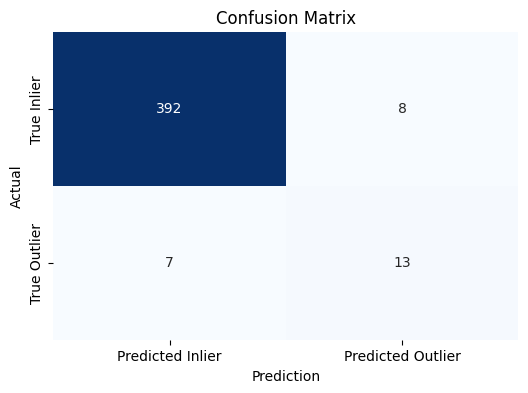

,precision,recall,f1-score,support
0,0.982,0.980,0.981,400
1,0.619,0.650,0.634,20
accuracy,0.964,0.964,0.964,1
macro avg,0.801,0.815,0.808,420
weighted avg,0.965,0.964,0.965,420


In [25]:
# Load libraries
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# Generate clustered data with synthetic noise
np.random.seed(2024)   # Catatan: ditambahkan agar hasil dapat direproduksi
X_clustered, _ = make_blobs(n_samples=400, centers=[[0, 0], [5, 5]], cluster_std=[0.5, 1.5], random_state=2024)
X_noise = np.random.uniform(low=-6, high=10, size=(20, 2))
X_combined = np.vstack([X_clustered, X_noise])
y_combined = np.array([0] * 400 + [1] * 20)

# Scale the data
X_scaled = scaler.fit_transform(X_combined)

# Apply Local Outlier Factor
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.05)
y_pred = lof.fit_predict(X_scaled)
y_pred_binary = np.where(y_pred == 1, 0, 1)

# Evaluate the predictions
print("\nExercise 2 Results:")
cm = confusion_matrix(y_combined, y_pred_binary)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted Inlier', 'Predicted Outlier'],
            yticklabels=['True Inlier', 'True Outlier'])
plt.xlabel('Prediction')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

report = classification_report(y_combined, y_pred_binary, output_dict=True)
report = pd.DataFrame(report).transpose()
styled_report = (report
    .style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
display(styled_report)

**Interpretasi:** LOF menandai 21 titik; **13 dari 20** anomali tertangkap (recall 0,65) dengan 8 alarm palsu (precision 0,619). Akurasi 0,964 tampak tinggi, tetapi model "selalu normal" sudah mendapat 400/420 = **0,952**, sehingga akurasi hanya 1,2 poin di atas *baseline*; kualitas sebenarnya terlihat pada precision dan recall kelas anomali (0,62 dan 0,65), jauh lebih rendah daripada pada data satu klaster (0,93) karena anomali yang jatuh di klaster longgar tidak terdeteksi.

### Latihan 3: *One-Class SVM* pada Data Sensor Manufaktur (Simulasi)
Dilatih hanya pada data normal, lalu mendeteksi *novelty* pada data campuran.

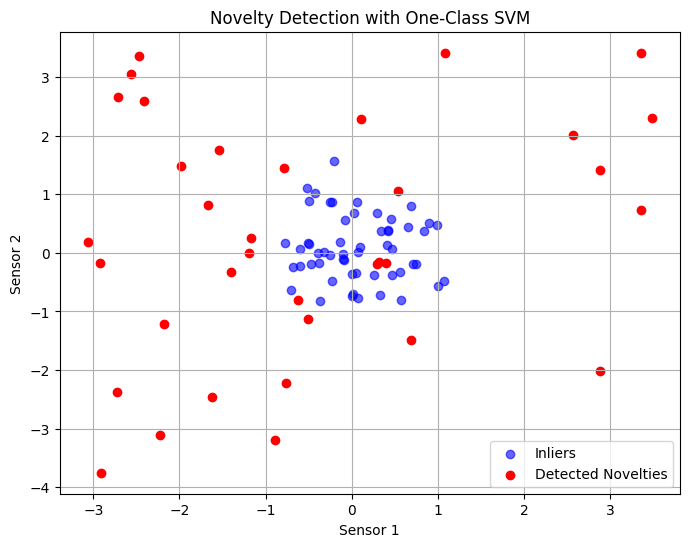

Normal dikenali benar: 51/60 | normal salah ditolak: 9 | novelty terdeteksi: 26/30


In [26]:
# Load libraries
from sklearn.svm import OneClassSVM
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Generate normal and novel data
np.random.seed(2024)   # Catatan: ditambahkan agar hasil dapat direproduksi
X_normal = np.random.normal(loc=0.0, scale=0.5, size=(300, 2))
X_novelty = np.random.uniform(low=-4, high=4, size=(30, 2))
X_train, X_test = train_test_split(X_normal, test_size=0.2, random_state=2024)
X_eval = np.vstack([X_test, X_novelty])

# Fit One-Class SVM on normal data
svm_model = OneClassSVM(kernel='rbf', gamma='scale', nu=0.05)
svm_model.fit(X_train)
y_pred = svm_model.predict(X_eval)

# Visualize predictions
plt.figure(figsize=(8, 6))
plt.scatter(X_eval[y_pred == 1][:, 0], X_eval[y_pred == 1][:, 1], color='blue', label='Inliers', alpha=0.6)
plt.scatter(X_eval[y_pred == -1][:, 0], X_eval[y_pred == -1][:, 1], color='red', label='Detected Novelties')
plt.title("Novelty Detection with One-Class SVM")
plt.xlabel("Sensor 1")
plt.ylabel("Sensor 2")
plt.legend()
plt.grid(True)
plt.show()

# Tambahan: ringkasan numerik (60 data uji normal pertama, 30 novelty terakhir)
y_eval_true = np.array([0] * len(X_test) + [1] * len(X_novelty))
tn, fp, fn, tp = confusion_matrix(y_eval_true, (y_pred == -1).astype(int)).ravel()
print(f'Normal dikenali benar: {tn}/{tn+fp} | normal salah ditolak: {fp} | novelty terdeteksi: {tp}/{tp+fn}')

**Interpretasi:** *One-Class SVM* dilatih hanya pada data normal (240 titik) mengenali **51 dari 60** data normal baru (85%), menolak 9 (15%), dan mendeteksi **26 dari 30** *novelty* (87%). Perhatikan `nu=0.05` mengendalikan proporsi **data latih** yang ditolak (≈ 5%), bukan jaminan untuk data baru; pada data latih sekecil ini batas cenderung cukup ketat sehingga data baru yang sama-sama normal ditolak lebih sering (15%). Empat *novelty* yang terlewat kemungkinan besar jatuh di dalam wilayah normal: dari kotak seragam [−4, 4]² (luas 64), wilayah ±3 simpangan baku (radius 1,5) hanya ≈ 11% luasnya, sehingga ≈ 3 dari 30 titik acak memang diperkirakan "tersamar".

---
## 9. Ringkasan Bab

Bab ini membahas **deteksi anomali** dengan tiga algoritma *unsupervised*, cara mengevaluasi hasilnya pada data yang sangat tak seimbang, dan cara menangani *outlier* yang ditemukan.

### Rangkuman Konsep dan Fungsi
| Subbab | Konsep utama | Kelas/Fungsi scikit-learn |
|---|---|---|
| Pemahaman dasar | *outlier* vs *novelty*; jenis anomali; `contamination` | `LocalOutlierFactor`, `predict()` (+1/−1) |
| *Isolation Forest* | isolasi lewat jalur pohon pendek; cepat, dimensi tinggi | `IsolationForest`, `decision_function` |
| *One-Class SVM* | *novelty detection*; `nu`, kernel | `OneClassSVM` |
| LOF | kepadatan lokal relatif; `n_neighbors`, `novelty=True` | `LocalOutlierFactor`, `negative_outlier_factor_` |
| Evaluasi | precision/recall/F1, ROC-AUC, PR-AUC; akurasi menyesatkan | `classification_report`, `roc_auc_score`, `average_precision_score` |
| Penanganan | hapus, ganti, *capping*, tandai, biarkan | `np.where`, `Series.clip`, `quantile` |
| Memilih algoritma | skala data, dimensi, variasi kepadatan, kebutuhan prediksi baru | – |
| Latihan | IF, LOF, OCSVM pada data simulasi | `StandardScaler`, `confusion_matrix` |

**Pesan utama:** tidak ada detektor anomali terbaik untuk semua kasus. Mulailah dengan *Isolation Forest*, gunakan LOF bila kepadatan lokal bervariasi, dan *One-Class SVM* bila hanya punya data normal; standardisasi fitur untuk metode berbasis jarak/kernel, evaluasi dengan metrik yang tahan ketidakseimbangan kelas (bukan akurasi), dan **selidiki anomali sebelum membuangnya**.